In [1]:
from langgraph.graph import StateGraph , START,END
from typing import TypedDict

In [2]:
class BATSMAN(TypedDict):
    run: int
    balls: int
    six: int
    four: int
    strike_rate: float
    Balls_per_boundary: float
    boundary_percentage: float
    summary: str
    final: str


In [3]:
def calculate_strike_rate(state: BATSMAN):
    sr = (state['run'] / state['balls']) * 100
    return {'strike_rate': sr}


def calculate_Balls_per_boundary(state: BATSMAN):
    bpb = state['balls'] / (state['four'] + state['six'])
    return {'Balls_per_boundary': bpb}


def calculate_boundary_percentage(state: BATSMAN):
    bp = (((state['four'] * 4) + (state['six'] * 6)) / state['run']) * 100
    return {'boundary_percentage': bp}


def Summary(state: BATSMAN):
    summ = f"""
    strike_rate - {state['strike_rate']}
    Balls_per_boundary - {state['Balls_per_boundary']}
    boundary_percentage - {state['boundary_percentage']}
    """
    return {'summary': summ}


def Final(state: BATSMAN):
    fin = """
    Thanks.....
    """
    return {'final': fin}

In [4]:
graph=StateGraph(BATSMAN)

graph.add_node('calculate_strike_rate',calculate_strike_rate)
graph.add_node('calculate_Balls_per_boundary',calculate_Balls_per_boundary)
graph.add_node('calculate_boundary_percentage',calculate_boundary_percentage)
graph.add_node('Summary',Summary)
graph.add_node('Final',Final)

In [5]:
graph.add_edge(START, 'calculate_strike_rate')
graph.add_edge(START, 'calculate_Balls_per_boundary')
graph.add_edge(START, 'calculate_boundary_percentage')


graph.add_edge('calculate_strike_rate', 'Summary')
graph.add_edge('calculate_Balls_per_boundary', 'Summary')
graph.add_edge('calculate_boundary_percentage', 'Summary')

graph.add_edge('Summary', 'Final')
graph.add_edge('Final', END)

workflow = graph.compile()

In [6]:
initial_state={
    'run':180,
    'four':20,
    'six':10,
    'balls':60
}
# final_state =
workflow.invoke(initial_state)
# print(final_state)

{'run': 180,
 'balls': 60,
 'six': 10,
 'four': 20,
 'strike_rate': 300.0,
 'Balls_per_boundary': 2.0,
 'boundary_percentage': 77.77777777777779,
 'summary': '\n    strike_rate - 300.0\n    Balls_per_boundary - 2.0\n    boundary_percentage - 77.77777777777779\n    ',
 'final': '\n    Thanks.....\n    '}

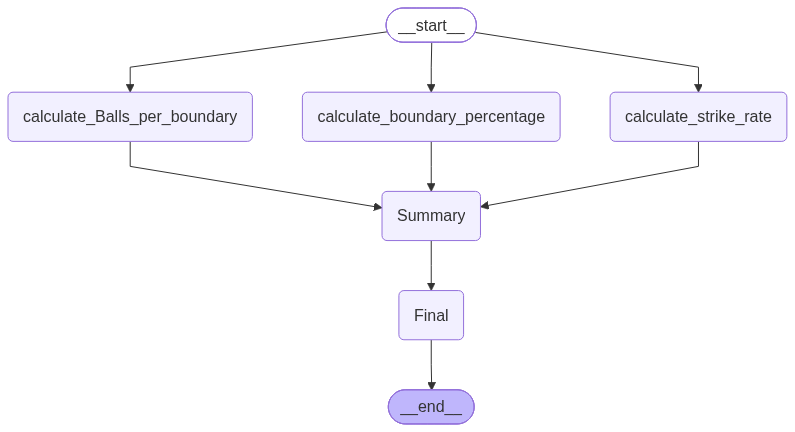

In [7]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())